In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
mplhep.style.use('ATLAS')


In [3]:


feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                'm_AllObjects',
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


len(feature_cols)


20

In [4]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [5]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_prompts = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_fakes = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_total = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [6]:
df_bkg_prompts_NoCategoryCut = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [6]:
len(df_bkg_prompts), len(df_bkg_fakes), len(df_bkg_total), len(df_bkg_prompts_NoCategoryCut)

NameError: name 'df_bkg_prompts_NoCategoryCut' is not defined

In [7]:
len(df_bkg_prompts)

1233

In [8]:
df_bkg_prompts.describe()

,"jet_pt[:,0]","jet_pt[:,1]",met_met,"ph_eta[:,0]","ph_eta[:,1]","ph_pt[:,0]","ph_pt[:,1]","ph_mlph_closest[:,0]","ph_mlph_closest[:,1]",diph_M,...,dr_lep_ph1,"ph_conversion_type[:,1]","ph_conversion_type[:,0]","ph_mphb70_closest[:,0]","ph_mphb70_closest[:,1]",m_AllObjects,jet_tagWeightBin_DL1r_Continuous_Max,dr_ph,eventNumber,weight
count,1.233000e+03,1.233000e+03,1233.000000,1233.000000,1233.000000,1233.000000,1233.000000,1.233000e+03,1.233000e+03,1.233000e+03,...,1233.000000,1233.000000,1233.000000,1.233000e+03,1.233000e+03,1.233000e+03,1233.000000,1233.000000,1.233000e+03,1233.000000
mean,2.089609e+05,1.199331e+05,59657.019531,0.008914,0.065022,166917.187500,58843.609375,2.246950e+05,1.153520e+05,2.238519e+05,...,1.923113,0.957826,0.868613,2.679202e+05,1.623095e+05,1.259549e+06,4.754258,2.383557,1.067026e+07,0.007480
std,1.632225e+05,1.106895e+05,60573.878906,1.193782,1.303602,155145.281250,58392.125000,2.229763e+05,1.146990e+05,2.086575e+05,...,0.995797,1.389258,1.349818,2.508206e+05,1.498669e+05,7.126979e+05,0.430701,1.120112,7.615337e+06,0.020861
min,3.190841e+04,2.907731e+04,1636.133789,-2.368942,-2.374777,20424.308594,20006.156250,1.014273e+04,7.402026e+03,-2.127024e+01,...,0.400286,0.000000,0.000000,1.429622e+04,1.408225e+04,2.428251e+05,4.000000,0.000000,2.925400e+04,-0.024786
25%,1.035836e+05,5.945891e+04,25378.705078,-0.884404,-0.986281,56124.234375,24581.031250,7.699359e+04,4.810346e+04,7.800108e+04,...,1.042981,0.000000,0.000000,1.005213e+05,6.892742e+04,7.550919e+05,5.000000,1.625873,3.441713e+06,0.000279
50%,1.625182e+05,8.840987e+04,42143.351562,0.030121,0.059909,115130.398438,37157.542969,1.574335e+05,7.901694e+04,1.628812e+05,...,1.863309,0.000000,0.000000,1.838537e+05,1.113307e+05,1.080045e+06,5.000000,2.525848,1.023043e+07,0.001935
75%,2.666455e+05,1.376525e+05,70797.187500,0.947641,1.114508,222046.265625,69265.031250,2.910796e+05,1.434615e+05,2.985466e+05,...,2.690799,2.000000,2.000000,3.341712e+05,1.984329e+05,1.612162e+06,5.000000,3.114812,1.725283e+07,0.009981
max,2.073713e+06,2.055059e+06,576597.750000,2.367152,2.363417,948702.562500,557621.062500,1.947087e+06,1.312120e+06,1.450211e+06,...,4.933883,5.000000,5.000000,1.688371e+06,1.490530e+06,6.172730e+06,5.000000,5.288041,3.138016e+07,0.321115


In [24]:
print(df_bkg_prompts.columns)

Index(['jet_pt[:,0]', 'jet_pt[:,1]', 'met_met', 'ph_eta[:,0]', 'ph_eta[:,1]',
       'ph_pt[:,0]', 'ph_pt[:,1]', 'ph_mlph_closest[:,0]',
       'ph_mlph_closest[:,1]', 'diph_M', 'event_nbjets70', 'dr_lep_ph0',
       'dr_lep_ph1', 'ph_conversion_type[:,1]', 'ph_conversion_type[:,0]',
       'ph_mphb70_closest[:,0]', 'ph_mphb70_closest[:,1]', 'm_AllObjects',
       'jet_tagWeightBin_DL1r_Continuous_Max', 'dr_ph', 'eventNumber',
       'weight'],
      dtype='object')


In [9]:

nfolds = 4
   
n_estimators = 20

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompts[feature_cols][df_bkg_prompts['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompts['weight'][df_bkg_prompts['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompts[feature_cols][df_bkg_prompts['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompts['weight'][df_bkg_prompts['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes[feature_cols][df_bkg_fakes['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes['weight'][df_bkg_fakes['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes[feature_cols][df_bkg_fakes['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes['weight'][df_bkg_fakes['eventNumber']%nfolds == fold]

    
        
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    print("\n\n\nSignal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ",len(X_bkg_train_prompts), len(w_bkg_train_prompts), len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_prompts), len(w_bkg_test_prompts), len(X_bkg_test_fakes), len(w_bkg_test_fakes))
    print(f"Fold {fold}:")
    print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    print(f"\nTesting: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    
    # Initialize XGBoost model for multi-class classification
    #model = XGBClassifier(objective='multi:softmax', num_class=3, use_label_encoder=False)
    #Set 1 of model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)

    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        objective="multi:softmax",  # Objective for multi-class classification
        num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    
    """
    for i in range(n_boosters):
            ypred_train = models[-1].predict_proba(X_train, iteration_range=(1, i+1))
            train_loss = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
            trainloss[fold].append(train_loss)

            ypred_test = models[-1].predict_proba(X_test, iteration_range=(1, i+1))
            test_loss = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
            testloss[fold].append(test_loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_Model{execution_count}_PCBTBinVariable_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    """
    




Signal train test(events,weights):  243054 243054 80846 80846
Background train test(events,weights):  925 925 2052 2052 308 308 674 674
Fold 0:
Training: Class 0: 243054, Class 1: 925, Class 2: 2052

Testing: Class 0: 80846, Class 1: 308, Class 2: 674
Train scores 0: [0.6543363619296622]
Test scores 0:  [0.587482319111468]
60



Signal train test(events,weights):  242986 242986 80914 80914
Background train test(events,weights):  925 925 2084 2084 308 308 642 642
Fold 1:
Training: Class 0: 242986, Class 1: 925, Class 2: 2084

Testing: Class 0: 80914, Class 1: 308, Class 2: 642
Train scores 1: [0.6543363619296622, 0.6453887572224568]
Test scores 1:  [0.587482319111468, 0.6290688142975411]
60



Signal train test(events,weights):  242824 242824 81076 81076
Background train test(events,weights):  927 927 2038 2038 306 306 688 688
Fold 2:
Training: Class 0: 242824, Class 1: 927, Class 2: 2038

Testing: Class 0: 81076, Class 1: 306, Class 2: 688
Train scores 2: [0.6543363619296622, 0.6453

In [10]:
# Works

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)

n_estimators = 20


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

60


In [11]:
print(len(trainloss[1]))
print(trainloss[1])
print(trainloss[1][1])
print(trainloss[1][0:10])



20
[1.0312831411770083, 0.9834997241293212, 0.9494188018850503, 0.9251357814392447, 0.9074346257386343, 0.8919807932141134, 0.8786197869335594, 0.8685716013398793, 0.8601805182317214, 0.8524561693321411, 0.8459251507282503, 0.8397901896212222, 0.8354927346407851, 0.8314116261096395, 0.8265817206561334, 0.8230196591492194, 0.8183193159413669, 0.814501625961557, 0.8115500149727801, 0.809284094724319]
0.9834997241293212
[1.0312831411770083, 0.9834997241293212, 0.9494188018850503, 0.9251357814392447, 0.9074346257386343, 0.8919807932141134, 0.8786197869335594, 0.8685716013398793, 0.8601805182317214, 0.8524561693321411]


In [26]:
print(testloss[2])

[1.0287378665858948, 0.9776873779613776, 0.9386125410651025, 0.9094242362164777, 0.8861215905871693, 0.8673859144209783, 0.8513957074575845, 0.8387415791860433, 0.8279886158323806, 0.8185528950341947, 0.8088308325065043, 0.8010353400869318, 0.7946297999824857, 0.7879602615859155, 0.7820104395871996, 0.7767236639614964, 0.7710848306275715, 0.7673012547093907, 0.7638014350237088, 0.760379857484591]


In [14]:
#print(testloss[0]), print(testloss[1]), print(testloss[2]), print(testloss[3])
#print(len(testloss[0])), print(len(testloss[1])), print(len(testloss[2])), print(len(testloss[3]))

for i in range(3):
    print(f'For fold {i}, mean value is {np.mean(testloss[i])}')

For fold 0, mean value is 0.8404331680590762
For fold 1, mean value is 0.8496819661824725
For fold 2, mean value is 0.83792030199515


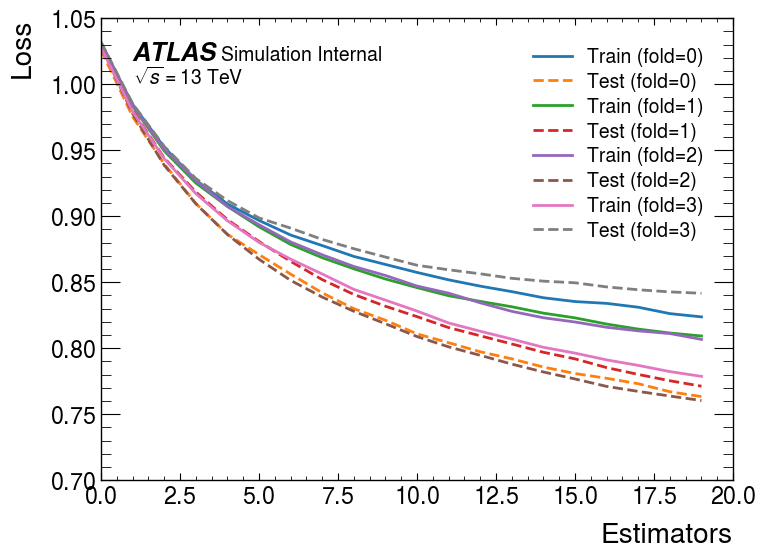

In [15]:
mplhep.style.use('ATLAS')
nbins = 10
nfolds = 4
n_estimators = 20
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [16]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompts[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in models]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in models]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in models]   #array of bdt scores

"""
print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompts['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)

print('Fold separated arrays for BDT scroes:')
print(results_bkg_prompts[1],results_bkg_fakes[1],results_sig[1])
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes:
0.19603923 0.65431046 0.70946884
Length sig:  323900
Length bkg:  1233
Length bkg:  2726


[0.383 0.215 0.402]


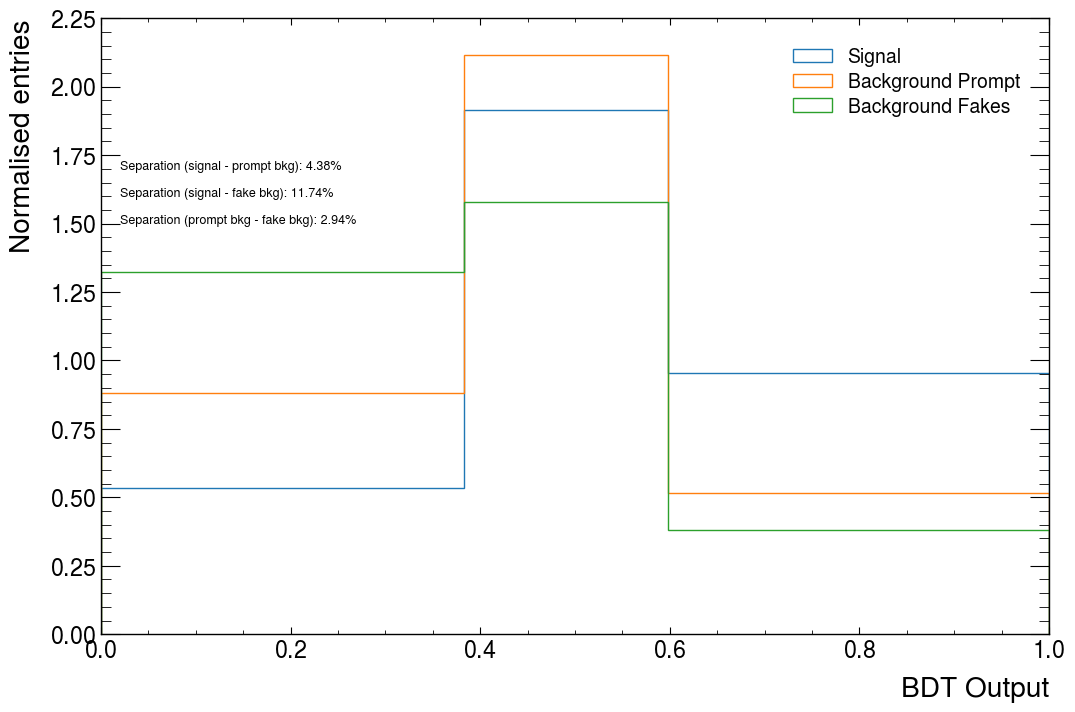

In [17]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompts['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.70, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.60, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.50, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

plt.savefig(f'separation_fittedbins_3class.pdf')
plt.legend()


In [18]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompts,df_bkg_fakes])

df_bkg_weight = np.concatenate([df_bkg_prompts['weight'],df_bkg_fakes['weight']])

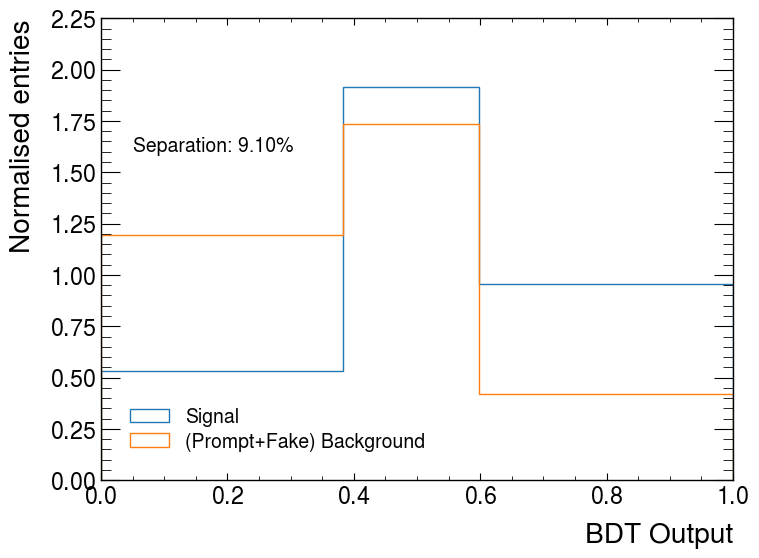

In [19]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='(Prompt+Fake) Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
plt.savefig(f'separation_fittedbins_3class_converged.pdf')
plt.legend()


# Something to make 3 folds more or less alright

In [117]:
from sklearn.model_selection import StratifiedKFold

In [118]:

# y contains class labels for df_sig, df_bkg_prompts, df_bkg_fakes

y = np.concatenate([np.zeros(len(df_sig)), np.ones(len(df_bkg_prompts)), 2 * np.ones(len(df_bkg_fakes))])
X = np.concatenate([df_sig[feature_cols], df_bkg_prompts[feature_cols], df_bkg_fakes[feature_cols]])
weights = np.concatenate([df_sig['weight'], df_bkg_prompts['weight'], df_bkg_fakes['weight']])

In [119]:
X, y , weights

(array([[1.50484406e+05, 7.35116797e+04, 9.40672891e+04, ...,
         6.62371887e+05, 5.00000000e+00, 3.37815928e+00],
        [8.68476719e+04, 8.01473359e+04, 8.22539922e+04, ...,
         4.40606248e+05, 5.00000000e+00, 1.65967226e+00],
        [1.81402812e+05, 6.82545078e+04, 7.48530234e+04, ...,
         7.90760612e+05, 5.00000000e+00, 2.83971953e+00],
        ...,
        [1.73386156e+05, 9.69388047e+04, 3.29928477e+04, ...,
         1.58484086e+06, 5.00000000e+00, 5.22452533e-01],
        [9.92263125e+04, 7.90560625e+04, 1.58462051e+04, ...,
         1.13195406e+06, 5.00000000e+00, 4.95215863e-01],
        [3.38086000e+05, 9.10800781e+04, 2.36494492e+04, ...,
         1.44277551e+06, 4.00000000e+00, 2.72036242e+00]]),
 array([0., 0., 0., ..., 2., 2., 2.]),
 array([1.3457049e-04, 1.1641563e-04, 1.2626748e-04, ..., 3.9550854e-04,
        2.2275517e-02, 1.7932385e-05], dtype=float32))

In [197]:

# Initialize StratifiedKFold with some suitable #folds like 3
nfolds = 5
skf = StratifiedKFold(n_splits=nfolds, shuffle=True, random_state=50) # changing random state changes some of the fold actions too

In [198]:
n_estimators = 30
n_folds = 5

In [199]:
SplitModels = []
for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    print(f'\nFirst 10 train and test indices are:{train_index[0:10]} and {test_index[0:10]}')
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    w_train, w_test = weights[train_index], weights[test_index]

    
    # Define the classifier for a 3-class classification
    SplitModel = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        objective="multi:softmax",  # Objective for multi-class classification
        num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    SplitModel.fit(X_train, y_train, sample_weight=np.abs(w_train))
    SplitModels.append(SplitModel)
    scores_train.append(SplitModel.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(SplitModel.score(X_test,y_test,sample_weight=w_test))  
    print(f'\nTrain scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(SplitModels[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)


First 10 train and test indices are:[ 0  2  3  4  5  6  7  9 10 11] and [ 1  8 12 31 38 44 45 46 50 57]

Train scores 0: [0.6543363619296622, 0.6453887572224568, 0.6512336962850245, 0.6586293095523534, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.6504225386049027, 0.6484858885382232, 0.6485596668932029, 0.6445885100723346, 0.6391329490008526, 0.6536373501407683, 0.6475869660711605, 0.6463203539607182, 0.6523475884110562, 0.6545131796760603, 0.6491884949004391, 0.6478841891242085, 0.6565955006382871, 0.6561471773275209, 0.6503371264799491, 0.6552096843377226, 0.6881162622315499, 0.6946648620652645, 0.6957495032364865, 0.6949802902869673, 0.6948958475854712, 0.6962646622308961, 0.6


Train scores 3: [0.6543363619296622, 0.6453887572224568, 0.6512336962850245, 0.6586293095523534, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.664946520877781, 0.6435953507707626, 0.6358849898746746, 0.6504225386049027, 0.6484858885382232, 0.6485596668932029, 0.6445885100723346, 0.6391329490008526, 0.6536373501407683, 0.6475869660711605, 0.6463203539607182, 0.6523475884110562, 0.6545131796760603, 0.6491884949004391, 0.6478841891242085, 0.6565955006382871, 0.6561471773275209, 0.6503371264799491, 0.6552096843377226, 0.6881162622315499, 0.6946648620652645, 0.6957495032364865, 0.6949802902869673, 0.6948958475854712, 0.6962646622308961, 0.6949451537387915, 0.6988070569321024, 0.6910729271042706, 0.6924152924694955, 0.6916711387002973, 0.687861

In [200]:
nfolds = 5
n_estimators = 30

In [201]:
# Works


testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)



for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = SplitModels[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = SplitModels[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

90


In [202]:
print(len(trainloss[1]))
print(trainloss[1])
print(trainloss[1][1])
print(trainloss[1][0:10])


30
[1.0292745264954626, 0.9818202738311664, 0.9475492149785455, 0.9220501434631012, 0.9024808968028497, 0.8865884484337221, 0.8740782571237642, 0.8629405132600609, 0.8531883944172574, 0.8436357567632439, 0.8371404432050633, 0.8295157057281971, 0.8249611348540905, 0.8199651680820463, 0.8158711957690452, 0.8105611470666683, 0.8064397177078244, 0.8029772986301006, 0.7985060274847539, 0.7950565626527716, 0.7917473837212239, 0.7887601725466196, 0.78612769483021, 0.7838789757453315, 0.7808618444572507, 0.778345103183711, 0.7766004698102948, 0.7740110725218824, 0.771718547182221, 0.7692192242153603]
0.9818202738311664
[1.0292745264954626, 0.9818202738311664, 0.9475492149785455, 0.9220501434631012, 0.9024808968028497, 0.8865884484337221, 0.8740782571237642, 0.8629405132600609, 0.8531883944172574, 0.8436357567632439]


In [203]:
#print(testloss[0]), print(testloss[1]), print(testloss[2]), print(testloss[3])
#print(len(testloss[0])), print(len(testloss[1])), print(len(testloss[2])), print(len(testloss[3]))

for i in range(n_folds):
    print(f'For fold {i}, mean value is {np.mean(testloss[i])}')

For fold 0, mean value is 0.827410220206883
For fold 1, mean value is 0.8291045193384577
For fold 2, mean value is 0.8273084832003395
For fold 3, mean value is 0.8266265341017618
For fold 4, mean value is 0.8840241027605952


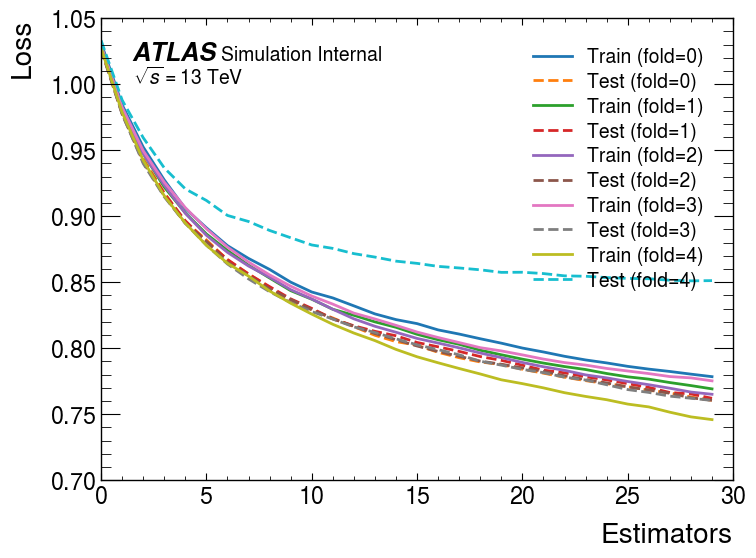

In [204]:
mplhep.style.use('ATLAS')

#n_estimators = 20
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [156]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompts[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in SplitModels]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in SplitModels]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in SplitModels]   #array of bdt scores

"""
print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompts['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)


print('Fold separated arrays for BDT scroes, first element:')
print('\nprompt bkg,      fake bkg,       signal')
print(results_bkg_prompts[1],'\t',results_bkg_fakes[1],'\t',results_sig[1])
print("\nLength sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes, first element:

prompt bkg,      fake bkg,       signal
0.18314281 	 0.6521647 	 0.53338856

Length sig:  323900
Length bkg:  1233
Length bkg:  2726


In [157]:
# Initialize lists to store results for signal and background
results_sig = np.zeros(len(df_sig))
results_bkg_prompts = np.zeros(len(df_bkg_prompts))
results_bkg_fakes = np.zeros(len(df_bkg_fakes))

# Iterate over each fold to get predictions
for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    # Get indices for the current fold
    sig_indices = df_sig['eventNumber'] % nfolds == fold
    bkg_prompts_indices = df_bkg_prompts['eventNumber'] % nfolds == fold
    bkg_fakes_indices = df_bkg_fakes['eventNumber'] % nfolds == fold
    
    # Predict probabilities for signal and background for the current fold
    results_sig[sig_indices] = SplitModels[fold].predict_proba(X_sig[sig_indices])[:, 0]
    results_bkg_prompts[bkg_prompts_indices] = SplitModels[fold].predict_proba(X_bkg_prompts[bkg_prompts_indices])[:, 0]
    results_bkg_fakes[bkg_fakes_indices] = SplitModels[fold].predict_proba(X_bkg_fakes[bkg_fakes_indices])[:, 0]

# At the end, results_sig, results_bkg_prompts, and results_bkg_fakes contain BDT scores for all samples.
print('Fold separated arrays for BDT scroes, first element:')
print('\nprompt bkg,      fake bkg,       signal')
print(results_bkg_prompts[1],'\t',results_bkg_fakes[1],'\t',results_sig[1])
print("\nLength sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes, first element:

prompt bkg,      fake bkg,       signal
0.18314281105995178 	 0.6521646976470947 	 0.5333885550498962

Length sig:  323900
Length bkg:  1233
Length bkg:  2726


[0.383 0.215 0.402]


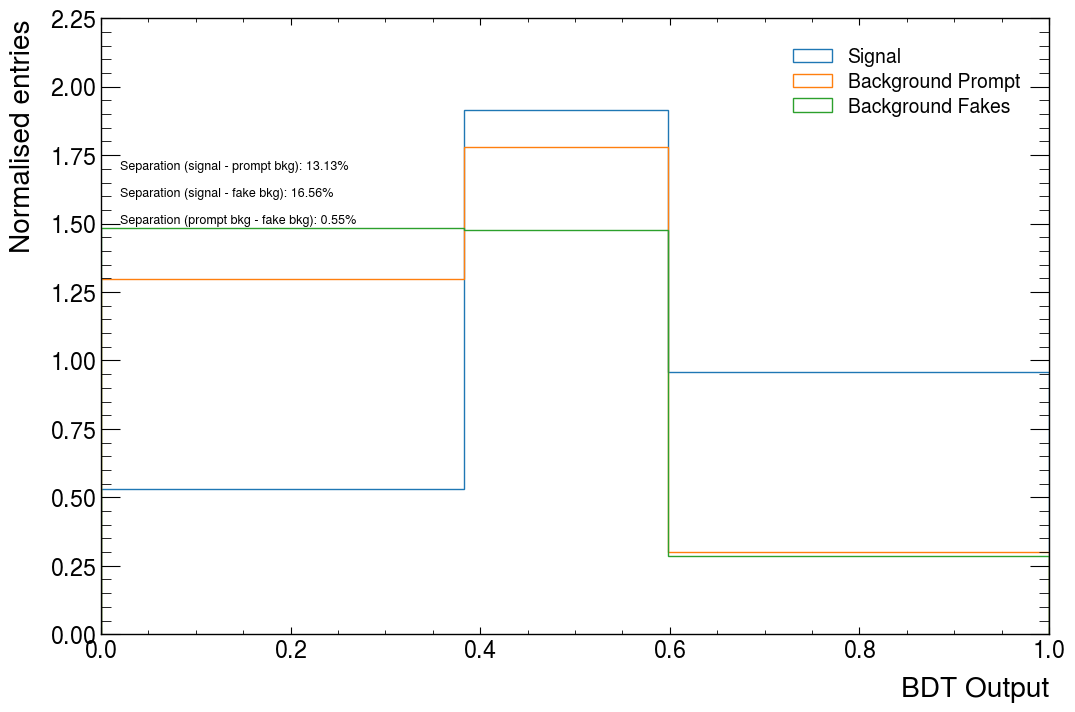

In [158]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompts['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.70, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.60, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.50, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


In [159]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompts,df_bkg_fakes])

df_bkg_weight = np.concatenate([df_bkg_prompts['weight'],df_bkg_fakes['weight']])

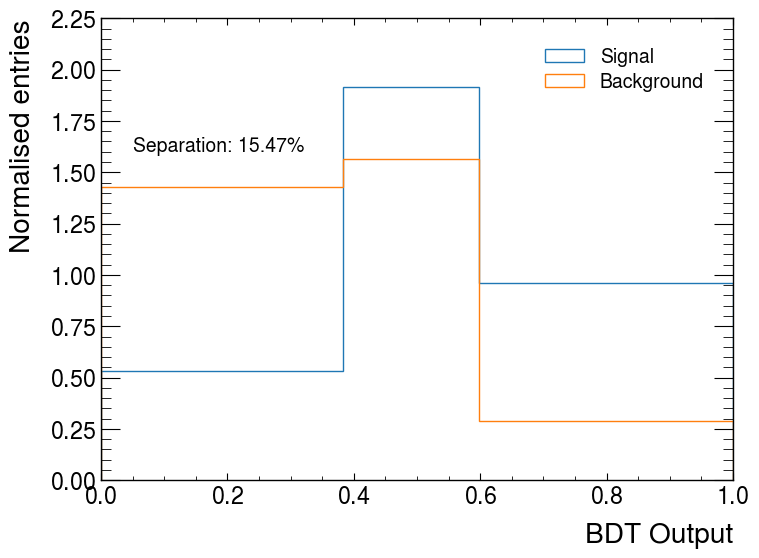

In [160]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()
